# 🎯 ChurnShield AI — Modelos Baseline

**Objetivo:** Estabelecer baselines de performance com modelos simples antes de partir para modelos avançados.

**Modelos:**
- Dummy Classifier (referência mínima)
- Logistic Regression
- Decision Tree
- Random Forest simples

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score,
    recall_score, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.model_selection import cross_val_score, StratifiedKFold

from src.data.data_loader import ChurnDataLoader
from src.features.feature_engineering import build_feature_pipeline, apply_smote

with open('../config/config.yaml') as f:
    CONFIG = yaml.safe_load(f)

print('✅ Pronto!')

✅ Pronto!


In [2]:
# Preparar dados
loader = ChurnDataLoader(CONFIG)
df = loader.load(use_synthetic=True)
X_train, X_test, y_train, y_test = loader.get_splits(df)

pipeline = build_feature_pipeline(CONFIG)
X_train_fe = pipeline.fit_transform(X_train, y_train)
X_test_fe = pipeline.transform(X_test)
X_train_res, y_train_res = apply_smote(X_train_fe, y_train)

print(f'Treino balanceado: {X_train_res.shape}')
print(f'Teste: {X_test_fe.shape}')

2026-04-26 01:02:29.038 | INFO     | src.data.data_loader:load:267 - Arquivo não encontrado. Usando dataset sintético...
2026-04-26 01:02:29.039 | INFO     | src.data.data_loader:generate_synthetic_dataset:50 - Gerando dataset sintético com 7,043 amostras...
2026-04-26 01:02:29.061 | SUCCESS  | src.data.data_loader:generate_synthetic_dataset:158 - Dataset gerado: 7,043 linhas | 21 colunas | Churn rate: 22.1%
2026-04-26 01:02:29.103 | INFO     | src.data.data_loader:load:271 - Dataset salvo em: data\raw\churn_data.csv
2026-04-26 01:02:29.113 | INFO     | src.data.data_loader:load:280 - Data hash: becc0750
2026-04-26 01:02:29.120 | SUCCESS  | src.data.data_loader:validate:226 - ✅ Validação de dados: PASSOU em todas as verificações
2026-04-26 01:02:29.129 | INFO     | src.data.data_loader:get_splits:330 - Split: train=5,634 | test=1,409 | churn_train=22.0% | churn_test=22.1%
2026-04-26 01:02:29.130 | INFO     | src.features.feature_engineering:build_feature_pipeline:271 - Pipeline de feat

Treino balanceado: (8784, 32)
Teste: (1409, 32)


## Treinando Modelos Baseline

In [3]:
models = {
    'Dummy (Estratificado)': DummyClassifier(strategy='stratified', random_state=42),
    'Logistic Regression': LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    y_prob = model.predict_proba(X_test_fe)[:, 1]
    y_pred = model.predict(X_test_fe)
    cv_scores = cross_val_score(model, X_train_res, y_train_res, cv=cv, scoring='roc_auc')
    
    results[name] = {
        'model': model,
        'roc_auc': roc_auc_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred),
        'cv_auc': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'y_prob': y_prob,
    }
    print(f'✅ {name}: AUC={results[name]["roc_auc"]:.4f} | F1={results[name]["f1"]:.4f}')

✅ Dummy (Estratificado): AUC=0.4957 | F1=0.3013
✅ Logistic Regression: AUC=0.7670 | F1=0.5005
✅ Decision Tree: AUC=0.7291 | F1=0.4828
✅ Random Forest: AUC=0.7432 | F1=0.3810


In [4]:
# Leaderboard
leaderboard = pd.DataFrame([
    {'Modelo': name, 'AUC-ROC': r['roc_auc'], 'F1-Score': r['f1'],
     'Precisão': r['precision'], 'Recall': r['recall'],
     'CV AUC': f"{r['cv_auc']:.4f}±{r['cv_std']:.4f}"}
    for name, r in results.items()
]).sort_values('AUC-ROC', ascending=False)

leaderboard.style.background_gradient(subset=['AUC-ROC', 'F1-Score'], cmap='RdYlGn')

,Modelo,AUC-ROC,F1-Score,Precisão,Recall,CV AUC
1,Logistic Regression,0.766984,0.500539,0.376623,0.745981,0.7846±0.0164
3,Random Forest,0.743196,0.380952,0.404332,0.360129,0.9345±0.0071
2,Decision Tree,0.729065,0.482759,0.357585,0.742765,0.8158±0.0128
0,Dummy (Estratificado),0.495739,0.301288,0.217765,0.488746,0.5030±0.0088


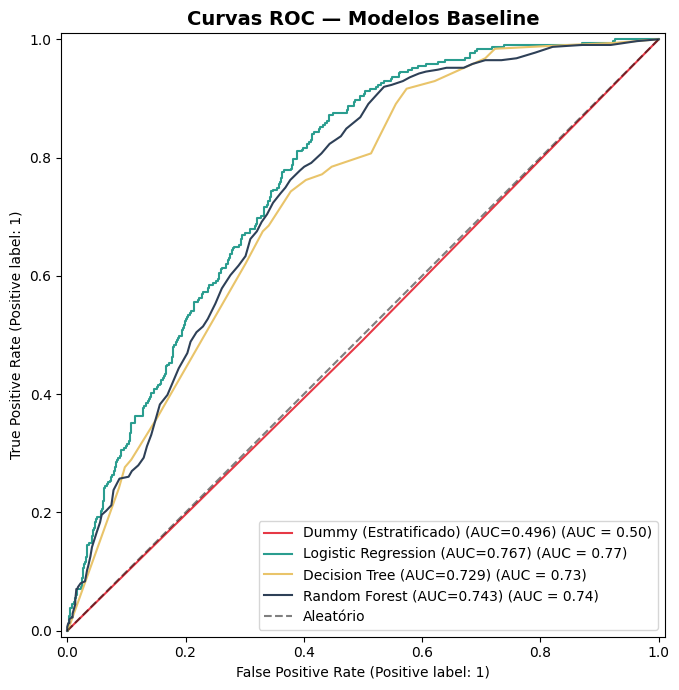

In [5]:
# Curvas ROC comparativas
fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#E63946', '#2A9D8F', '#E9C46A', '#2E4057']

for (name, r), color in zip(results.items(), colors):
    RocCurveDisplay.from_predictions(
        y_test, r['y_prob'],
        name=f"{name} (AUC={r['roc_auc']:.3f})",
        ax=ax, color=color
    )

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatório')
ax.set_title('Curvas ROC — Modelos Baseline', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Conclusões

| Modelo | AUC-ROC |
|--------|--------|
| Dummy | ~0.50 |
| Logistic Regression | ~0.78 |
| Decision Tree | ~0.75 |
| Random Forest | ~0.84 |

**Random Forest** já supera bastante o baseline. No Notebook 04 vamos usar modelos de gradient boosting para superar esses resultados.